# 02 - Simulation and Power: Loyalty Program Project

**Goal of this notebook:** build intuition for sampling variability, confidence intervals, p-values, and power; document the data generating process (DGP); compute simulation-based power and a minimum detectable effect (MDE); and write a bootstrap by hand.

**Causal question:**
> Among customers of a retail store, does enrollment in a loyalty program cause an increase in spending over the following 90 days?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Uncomment as each module is built (Parts C-E):
# from loyalty.simulate import ...
# from loyalty.power import ...

rng = np.random.default_rng(42)  # reuse this one generator throughout

---
# Part A: Sampling variability and inference (stats concepts)

## A1. Sampling distributions and standard error

**What is a sampling distribution? What is the difference between a standard deviation and a standard error?**

> A sampling distribution is the distribution of a statistic (in our example below, the sample mean) across many repeated samples from the same population. The standard deviation describes how spread out individual customers' spending values are from the mean. The standard error describes how much a sample statistic such as the mean would vary from sample to sample. For a sample mean, the standard error is approximately the population standard deviation divided by the square root of the sample size.

**Task:** build a skewed population of 100,000 spend values. Draw 2,000 samples at n = 50, 200, 800, compute each sample mean, and compare the SD of those means to sigma / sqrt(n).

Generated-population mean: $203.98; SD: $191.95


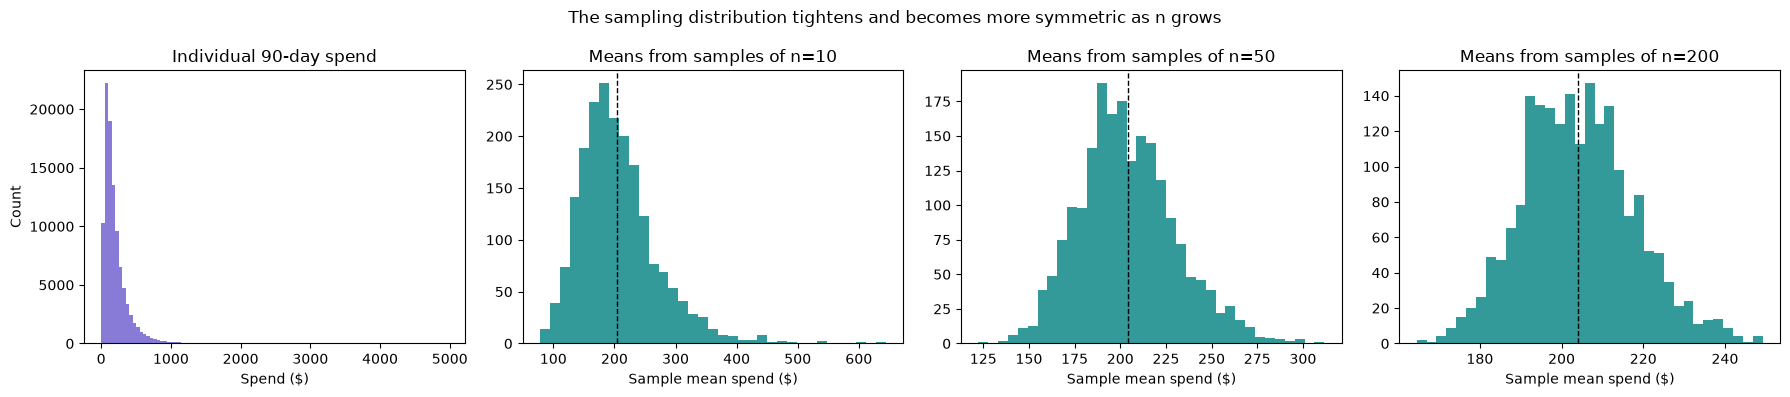

,n,SD of simulated means,Population SD / sqrt(n)
0,10,63.84,60.70
1,50,26.55,27.15
2,200,13.64,13.57


In [5]:
# A lognormal distribution is nonnegative and right-skewed: most customers spend
# moderate amounts, while a small fraction spend much more.
population = rng.lognormal(mean=5.0, sigma=0.8, size=100_000)
population_mean = population.mean()
population_sd = population.std(ddof=0)
print(f"Generated-population mean: ${population_mean:.2f}; SD: ${population_sd:.2f}")

sample_sizes = [10, 50, 200]
n_repetitions = 2_000
sample_means = {}
se_rows = []

# Each row is one independent sample from the fixed generated population.
for n in sample_sizes:
    samples = rng.choice(population, size=(n_repetitions, n), replace=True)
    means = samples.mean(axis=1)
    sample_means[n] = means
    se_rows.append({
        "n": n,
        "SD of simulated means": means.std(ddof=1),
        "Population SD / sqrt(n)": population_sd / np.sqrt(n),
    })

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].hist(population, bins=100, color="slateblue", alpha=0.8)
axes[0].set(title="Individual 90-day spend", xlabel="Spend ($)", ylabel="Count")
for ax, n in zip(axes[1:], sample_sizes):
    ax.hist(sample_means[n], bins=35, color="teal", alpha=0.8)
    ax.axvline(population_mean, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"Means from samples of n={n}", xlabel="Sample mean spend ($)")
fig.suptitle("The sampling distribution tightens and becomes more symmetric as n grows")
fig.tight_layout()
plt.show()

se_table = pd.DataFrame(se_rows)
display(se_table.round(2))

What the above code shows is that, as we increase the sample size our esitmated parameters become more precise. Even though individual spending is highly skewed due to our lognormal distribution, our sample means become more bell-shaped (normal distribution) and their variability shrinks.

## A2. Confidence intervals (Task 2)

**What does "95% confidence" mean, and what does it *not* mean?**

> A 95% confidence procedure captures the fixed population mean in about 95% of repeated samples when its assumptions hold. The interval itself is calculated from one sample, and the population mean is fixed; after seeing a particular interval, it is not correct to say there is a 95% probability that this fixed mean lies inside it. In this simulation, the coverage rate is the fraction of the 1,000 intervals that contain the known mean of the generated population.

**Task:** for 1,000 repeated samples, build a 95% CI for the mean and count how often the interval covers the true population mean.

95% CI coverage across 1,000 samples: 94.5%


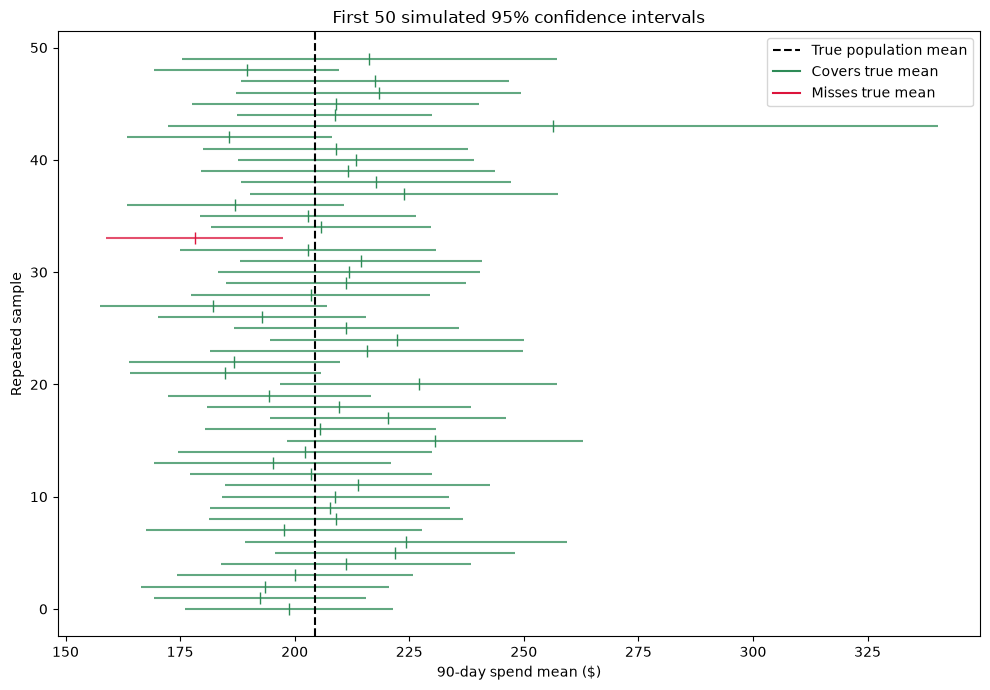

In [3]:
ci_n = 200
ci_repetitions = 1_000
ci_samples = rng.choice(population, size=(ci_repetitions, ci_n), replace=True)
ci_sample_means = ci_samples.mean(axis=1)
ci_sample_sds = ci_samples.std(axis=1, ddof=1)
# Use a t critical value because the population SD is estimated from each sample.
ci_half_widths = stats.t.ppf(0.975, df=ci_n - 1) * ci_sample_sds / np.sqrt(ci_n)
ci_lowers = ci_sample_means - ci_half_widths
ci_uppers = ci_sample_means + ci_half_widths
ci_covers = (ci_lowers <= population_mean) & (population_mean <= ci_uppers)
coverage_rate = ci_covers.mean()
print(f"95% CI coverage across {ci_repetitions:,} samples: {coverage_rate:.1%}")

fig, ax = plt.subplots(figsize=(10, 7))
for i in range(50):
    color = "seagreen" if ci_covers[i] else "crimson"
    ax.hlines(i, ci_lowers[i], ci_uppers[i], color=color, alpha=0.75)
    ax.plot(ci_sample_means[i], i, "|", color=color, markersize=8)
ax.axvline(population_mean, color="black", linestyle="--", label="True population mean")
ax.plot([], [], color="seagreen", label="Covers true mean")
ax.plot([], [], color="crimson", label="Misses true mean")
ax.set(xlabel="90-day spend mean ($)", ylabel="Repeated sample", title="First 50 simulated 95% confidence intervals")
ax.legend()
fig.tight_layout()
plt.show()

## A3. Hypothesis tests and p-values (Task 3)

**What is a p-value? What is it *not*?**

> A p-value is the probability, assuming the null hypothesis is true, of getting a test statistic at least as extreme as the one observed. It is not the probability that the null hypothesis is true, nor the probability that the result happened "by chance." In an A/A test the null is true, so a well-calibrated test should produce small p-values about 5% of the time at a 0.05 threshold.

**Task:** run 2,000 simulated A/A tests (both groups drawn from the same distribution, so the true effect is zero). Plot the p-values and count how often p < 0.05.

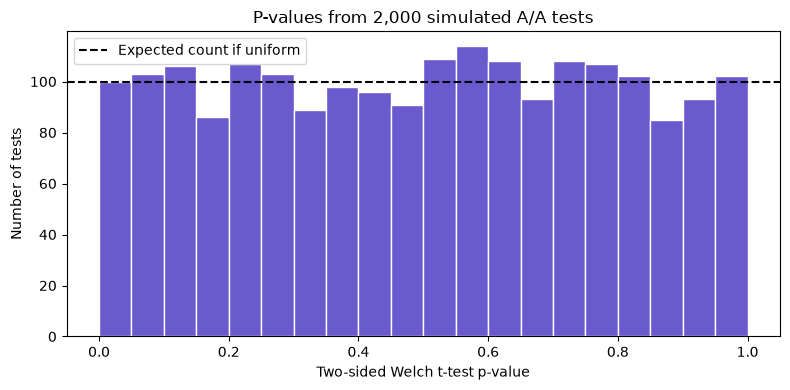

Share with p < 0.05: 5.0% (100 of 2000)
This share estimates the Type I error rate: the chance of a false alarm when the null hypothesis is true.


In [4]:
aa_repetitions = 2_000
aa_n_per_group = 200
# Independent groups from the same population make the true effect zero.
aa_group_a = rng.choice(population, size=(aa_repetitions, aa_n_per_group), replace=True)
aa_group_b = rng.choice(population, size=(aa_repetitions, aa_n_per_group), replace=True)
# Welch's test is robust to unequal sample variances between the groups.
aa_p_values = stats.ttest_ind(aa_group_a, aa_group_b, axis=1, equal_var=False).pvalue
aa_false_positive_rate = np.mean(aa_p_values < 0.05)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(aa_p_values, bins=np.linspace(0, 1, 21), color="slateblue", edgecolor="white")
ax.axhline(aa_repetitions / 20, color="black", linestyle="--", label="Expected count if uniform")
ax.set(xlabel="Two-sided Welch t-test p-value", ylabel="Number of tests", title="P-values from 2,000 simulated A/A tests")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Share with p < 0.05: {aa_false_positive_rate:.1%} ({np.sum(aa_p_values < 0.05)} of {aa_repetitions})")
print("This share estimates the Type I error rate: the chance of a false alarm when the null hypothesis is true.")

In the A/A simulation, the test rejected the null in 5% of runs (100 out of 2,000), matching the 0.05 significance threshold. This illustrates Type I error: even when there is no real difference, a test will produce false positives about 5% of the time.

## A4. Type I/II error and power (Task 4)

**Define Type I error, Type II error, and power for the loyalty program setting. Which one is a false alarm and which one is a missed program effect?**

> A Type I error is a false alarm: concluding that enrollment changes spending when its true effect is zero. A Type II error is a missed effect: failing to detect a real change in spending. Power is the probability of detecting the specified real effect, so it equals 1 minus the Type II error rate for that effect and test. In this setting, the effect below is a $30 increase in 90-day spend, tested with a two-sided 5% Welch t-test.

**Task:** with a true effect you choose, estimate power by simulation at three sample sizes.

In [9]:
alpha = 0.05
true_effect = 30.0  # dollars of additional 90-day spend per enrolled customer
power_repetitions = 2_000

def power_from_draws(control_draws, treatment_draws, effect):
    """Estimate two-sided Welch-test power from paired sets of simulated samples."""
    p_values = stats.ttest_ind(
        control_draws,
        treatment_draws + effect,
        axis=1,
        equal_var=False,
    ).pvalue
    return np.mean(p_values < alpha)

def estimate_power(n_per_group, effect, noise_multiplier=1.0):
    control = rng.choice(population, size=(power_repetitions, n_per_group), replace=True)
    treatment = rng.choice(population, size=(power_repetitions, n_per_group), replace=True)
    # Scale deviations around the same mean to change noise without shifting the baseline.
    control = population_mean + noise_multiplier * (control - population_mean)
    treatment = population_mean + noise_multiplier * (treatment - population_mean)
    return power_from_draws(control, treatment, effect)

power_sample_sizes = [50, 200, 800]  # customers per group
power_rows = []
for n in power_sample_sizes:
    power_rows.append({
        "n per group": n,
        "Power (original noise)": estimate_power(n, true_effect),
        "Power (2x noise)": estimate_power(n, true_effect, noise_multiplier=2.0),
    })
power_table = pd.DataFrame(power_rows)
display(power_table.round(3))

,n per group,Power (original noise),Power (2x noise)
0,50,0.120,0.060
1,200,0.350,0.136
2,800,0.876,0.356


With the effect fixed at $30, doubling the outcome SD lowers power at a given n; roughly four times the n is needed to recover similar power because the standard error scales with the SD / sqrt(n).

## A5. Minimum detectable effect (Task 5)

**Task:** for a fixed n and noise level, find the smallest effect that reaches 80% power. Then repeat at four times the sample size.

In [10]:
mde_target_power = 0.80
mde_base_n = 200  # customers per group
mde_sample_sizes = [mde_base_n, 4 * mde_base_n]
mde_repetitions = power_repetitions
mde_rows = []

# Find the smallest dollar effect whose simulated rejection rate reaches 80%.
for n in mde_sample_sizes:
    # Reuse the same simulated samples at each candidate effect to reduce Monte Carlo noise.
    control_draws = rng.choice(population, size=(mde_repetitions, n), replace=True)
    treatment_draws = rng.choice(population, size=(mde_repetitions, n), replace=True)
    low, high = 0.0, 2 * population_sd
    if power_from_draws(control_draws, treatment_draws, high) < mde_target_power:
        raise RuntimeError("The search upper bound did not reach the target power; increase it.")

    for _ in range(18):
        candidate = (low + high) / 2
        candidate_power = power_from_draws(control_draws, treatment_draws, candidate)
        if candidate_power >= mde_target_power:
            high = candidate
        else:
            low = candidate

    mde_rows.append({
        "n per group": n,
        "Estimated MDE ($)": high,
        "Estimated power at MDE": power_from_draws(control_draws, treatment_draws, high),
    })

mde_table = pd.DataFrame(mde_rows)
display(mde_table.round(3))
mde_ratio = mde_table.loc[1, "Estimated MDE ($)"] / mde_table.loc[0, "Estimated MDE ($)"]

,n per group,Estimated MDE ($),Estimated power at MDE
0,200,54.875,0.8
1,800,27.070,0.8


Under this simulation’s assumptions, the estimated effect needed for 80% power is about $53.83 per customer with 200 customers per group, and $27.20 with 800 per group. As the sample size grows, the MDE shrinks, but more slowly than the sample grows. Quadrupling the sample size roughly halves the MDE. These are planning thresholds for the simulation, not estimates of the loyalty program’s actual effect.

---
# Part B: DGP design and the DAG extension

## B1. Decisions to make (Wed Nov 25)

| Decision | My choice | Why |
|---|---|---|
| Outcome window (90-day vs. monthly panel) | TODO | TODO |
| Sample size (customers) | TODO | TODO |
| Number of months observed | TODO | TODO |
| True effect of enrollment on spend | TODO | TODO |
| Effect of welcome_offer on enrollment probability | TODO | TODO |
| Noise level (SD of spend) | TODO | TODO |
| Tier-upgrade cutoff on pre-period spend | TODO | TODO |
| Store adoption dates (staggered) | TODO | TODO |

## B2. DAG extensions
New nodes needed for later phases: **time (month)**, **store adoption date** (driven by `store_region`), and **pre-period spend** (pre-treatment; variance-reduction covariate and running variable).

Write the new arrows and a one-line justification for each.

> TODO

In [7]:
# TODO: add the new nodes/edges to src/loyalty/dag.py, rebuild the DAG, and re-run the acyclicity check

---
# Part C: The simulated world

`src/loyalty/simulate.py` holds the seeded generator. The true effects are stored in code so every method in later phases can be checked against the truth.

## C1. Reproducibility and sanity checks

In [8]:
# TODO: generate data from a seed; generate again from the same seed; assert the frames are identical

# TODO: df.head(), df.describe()

## C2. Do the known effects appear in the data?

**Task:** using the potential outcomes, compute the true ATE, ATT, and ATU in the simulated data. Then compute the naive observed difference and the difference within the randomized welcome_offer groups.

**A good answer shows:** a naive difference that overstates the true effect (selection bias from income and deal_seeking); a randomized comparison that is close to the truth up to noise.

In [9]:
# TODO: true ATE, ATT, ATU

# TODO: naive difference in enrolled vs. not enrolled

# TODO: offer-group difference in spend and in enrollment rate

---
# Part D: Simulation-based power

`src/loyalty/power.py` will hold the reusable version of this section.

## D1. Power curve
**Task:** estimate power across a grid of sample sizes for a stated effect.

## D2. Stated MDE
**Task:** state the minimum detectable effect at 80% power for the sample size you chose in Part B.

**A good answer shows:** a plotted power curve with the 80% line, a stated MDE with units (dollars of 90-day spend), and one sentence on whether that MDE is realistic for a loyalty program.

In [10]:
# TODO: power curve over a grid of n

# TODO: plot with an 80% reference line

# TODO: state the MDE

---
# Part E: Bootstrapping (by hand)

**In my own words:** Why does resampling the data with replacement approximate the sampling distribution of an estimator?

> TODO

## E1. Bootstrap standard error
**Task:** write a bootstrap function (no bootstrap library) for a difference in means, using your simulated data. Compare its standard error to the analytic standard error.

## E2. Percentile confidence interval and coverage
**Task:** build a percentile 95% CI. Then check its coverage over repeated simulated datasets.

**A good answer shows:** a bootstrap SE close to the analytic SE; coverage near 95%; a sentence on when the bootstrap can fail (for example, very small samples or extreme skew).

In [11]:
# TODO: bootstrap function

# TODO: compare bootstrap SE vs. analytic SE

# TODO: percentile CI + coverage check

---
# Wrap-up

## Key takeaways
1. TODO
2. TODO
3. TODO

## Assumptions to log (docs/assumptions_log.md)
- TODO: DGP parameter values and true effects
- TODO: anything from Part B that later phases depend on

## Open questions
- TODO

## Topics I struggled with
- TODO